# Week 2 practical: where the actuator ceiling binds, and what a horizon buys

**240MAR45 Reinforcement Learning in Robotics** | MSc Automatic Control and Robotics, UPC

The lecture put one controller on the torque-limited pendulum and watched it fail from the
hanging position. Today you measure that failure instead of looking at it. The first half turns
the region-of-attraction figure of the notes into numbers, tests the colleague's proposal of
conceptual question 1.1 (raise $Q$ and the pendulum swings up), and finds the torque at which
hanging-at-rest is finally captured. The second half closes the loop with nonlinear MPC,
sweeps the horizon, and asks what an LQR terminal cost does to the horizon you need.

## Objectives

1. Implement the saturated LQR law and measure its region of attraction on the true nonlinear
   plant.
2. Show with a number that a larger gain leaves the captured region where it was.
3. Find the smallest torque bound under which hanging-at-rest ends upright, and compare it with
   the static holding torque $mg\ell$.
4. Implement the MPC objective as dynamic programming on a truncated horizon, and find the
   shortest horizon that swings the pendulum up.
5. Measure what that horizon costs in solve time, and what an LQR terminal cost changes.

## Session plan

Everything here is done in the session, and there is no homework. The quiz at the end is the only
thing evaluated.

| Part | Minutes |
|------|---------|
| 1 to 3. Smoke test, recap, the pre-written plant | 10 |
| 4. Blanked core A, the saturated LQR law | 10 |
| 5. Region of attraction, the gain, the ceiling (Checkpoints 1 to 3) | 20 |
| 6. Blanked core B, the MPC objective | 10 |
| 7. Horizon sweep, solve time, terminal cost (Checkpoints 4 to 6) | 20 |
| 8. Analysis | 5 |
| The quiz, on the university course page | 15 |

The heaviest cell carries 108 661 initial conditions through 2400 integration steps as two
arrays, and it takes around half a minute on a laptop. Each MPC sweep takes about as long.
If you finish early, the challenge problem of the Week 2 notes takes the terminal-cost question
to its quantitative end. That one is formative, it will not enter in the quizz.

## 1. Smoke test (run this first)

If any line below fails, raise your hand before reading further.

In [ ]:
import sys
import time

t0 = time.time()

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are, solve_discrete_are
from scipy.optimize import minimize

print(f"python      {sys.version.split()[0]}")
print(f"numpy       {np.__version__}")
print(f"scipy       {scipy.__version__}")
print(f"matplotlib  {matplotlib.__version__}")

# One random-torque rollout of a pendulum, integrated with the explicit Euler rule. Section 3
# replaces it with the RK4 model the whole session uses.
rng = np.random.default_rng(0)
x = np.array([0.0, 0.0])
for _ in range(200):
    u = rng.uniform(-5.0, 5.0)
    x = x + 0.01 * np.array([x[1], u - 0.1 * x[1] - 9.81 * np.sin(x[0])])
print(f"\nrandom-torque rollout ends at theta = {x[0]:+.3f} rad, thetadot = {x[1]:+.3f} rad/s")
print(f"\nsetup OK  ({time.time() - t0:.1f} s)")

python      3.13.15
numpy       2.1.3
scipy       1.16.3
matplotlib  3.10.0

random-torque rollout ends at theta = +0.018 rad, thetadot = -0.123 rad/s

setup OK  (0.5 s)


## 2. Recap

The plant is the pendulum of notes section 3.1, with $\theta = 0$ hanging and $\theta = \pi$
upright,

$$ m\ell^2 \ddot\theta = u - b\dot\theta - mg\ell \sin\theta, \qquad |u| \le u_{\max}. $$

Its linearisation about the upright has a stabilising LQR gain $K$, but the law the plant actually
receives is that gain behind a saturation,

$$ u = \operatorname{clip}\!\big(-K e,\, -u_{\max},\, u_{\max}\big), \qquad
   e = \big(\operatorname{wrap}(\theta - \pi),\ \dot\theta\big). $$

The clip is where the Riccati theory stops describing the closed loop. The first half of
the session measures how much that costs. The second half replaces the fixed law by MPC, which
re-solves a finite-horizon problem from the measured state at every period,

$$ \min_{u_0,\dots,u_{N-1}} \; \sum_{i=0}^{N-1} g(x_{i+1}, u_i) + \hat J(x_N), \qquad
   x_{i+1} = f(x_i, u_i), \quad |u_i| \le u_{\max}, $$

applies $u_0$, and discards the rest. That is the Bellman recursion cut at $N$ steps, with
$\hat J$ standing in for the tail that was not computed (notes section 4).

Background reading: notes sections 3.2 and 3.3 (the saturated law and its region of attraction),
4.3 to 4.5 (the MPC algorithm, the horizon, and what MPC costs), and the concept notes
`Torque-limited pendulum`, `LQR`, `MPC` and `Terminal cost approximation`.

## 3. Pre-written infrastructure

The course parameters, the RK4 step of the true nonlinear plant, and the linearisation about the
upright. The step is written so that `th`, `om` and `u` may be scalars or arrays of any matching
shape, which is what lets the region-of-attraction sweep run as array code.

In [ ]:
m, l, b, g = 1.0, 1.0, 0.1, 9.81
U_MAX = 5.0                    # the torque bound of the lecture, below m g l = 9.81 N m


def rk4_step(th, om, u, dt):
    """One RK4 step of the nonlinear pendulum with u held over the step. Works on arrays."""
    def acc(th, om):
        return (u - b * om - m * g * l * np.sin(th)) / (m * l**2)
    k1t, k1o = om, acc(th, om)
    k2t, k2o = om + 0.5 * dt * k1o, acc(th + 0.5 * dt * k1t, om + 0.5 * dt * k1o)
    k3t, k3o = om + 0.5 * dt * k2o, acc(th + 0.5 * dt * k2t, om + 0.5 * dt * k2o)
    k4t, k4o = om + dt * k3o, acc(th + dt * k3t, om + dt * k3o)
    th_next = th + (dt / 6.0) * (k1t + 2 * k2t + 2 * k3t + k4t)
    om_next = om + (dt / 6.0) * (k1o + 2 * k2o + 2 * k3o + k4o)
    return th_next, om_next


def wrap(a):
    """Wrap an angle to [-pi, pi)."""
    return (a + np.pi) % (2 * np.pi) - np.pi


# Linearisation about the UPRIGHT, with phi = theta - pi, so sin(theta) is approximately -phi.
A_c = np.array([[0.0, 1.0], [g / l, -b / (m * l**2)]])
B_c = np.array([[0.0], [1.0 / (m * l**2)]])


def lqr_gain_continuous(A, B, Q, R):
    """Continuous-time LQR gain K = R^{-1} B' P, with P from the algebraic Riccati equation."""
    P = solve_continuous_are(A, B, Q, R)
    return np.linalg.solve(R, B.T @ P)


Q_LQR, R_LQR = np.diag([10.0, 1.0]), np.array([[1.0]])
K = lqr_gain_continuous(A_c, B_c, Q_LQR, R_LQR)
print(f"K = {K.ravel().round(2)}   (expected [20.12, 6.32])")

K = [20.12  6.32]   (expected [20.12, 6.32])


### Region-of-attraction harness (nothing to fill in here)

The grid and the capture test are those of the notes figure `pendulum_lqr_roa`:
$\theta \in [-\pi, 3\pi]$ at 361 points, $\dot\theta \in [-12, 12]$ rad/s at 301 points, RK4 at
$\Delta t = 5$ ms for 12 s, and a run counts as captured when it ends with
$|\operatorname{wrap}(\theta - \pi)| < 0.05$ rad and $|\dot\theta| < 0.2$ rad/s. Every number in
that specification moves the percentages you are about to compute, so a region-of-attraction
statistic describes the sampling as much as it describes the controller (notes section 3.3).

In [ ]:
DT_ROA, T_ROA = 0.005, 12.0
TH_GRID = np.linspace(-np.pi, 3 * np.pi, 361)
OM_GRID = np.linspace(-12.0, 12.0, 301)
LOW_ENERGY = 2.0               # the band |thetadot| <= 2 rad/s


def simulate_closed_loop(th0, om0, K, u_max, T=T_ROA, dt=DT_ROA):
    """Carry every initial condition through the saturated LQR loop at once.

    th0, om0 and u_max broadcast against each other. Returns the final (th, om).
    """
    th, om = np.array(th0, dtype=float), np.array(om0, dtype=float)
    for _ in range(int(round(T / dt))):
        u = saturated_lqr(th, om, K, u_max)
        th, om = rk4_step(th, om, u, dt)
    return th, om


def is_captured(th, om):
    return (np.abs(wrap(th - np.pi)) < 0.05) & (np.abs(om) < 0.2)


def roa_sweep(K, u_max, th_grid=TH_GRID, om_grid=OM_GRID):
    """Returns the boolean capture map (n_om, n_th), the whole-box and low-energy fractions."""
    TH, OM = np.meshgrid(th_grid, om_grid)
    cap = is_captured(*simulate_closed_loop(TH, OM, K, u_max))
    band = np.abs(OM) <= LOW_ENERGY
    return cap, cap.mean(), cap[band].mean()


def plot_roa(cap, title=""):
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    ax.imshow(cap, origin="lower", aspect="auto", cmap="Blues", vmin=-0.3, vmax=1.2,
              extent=[TH_GRID[0], TH_GRID[-1], OM_GRID[0], OM_GRID[-1]])
    for yy in (-LOW_ENERGY, LOW_ENERGY):
        ax.axhline(yy, color="#D55E00", lw=1.0, ls="--")
    for xx in (np.pi,):
        ax.axvline(xx, color="0.3", lw=0.8, ls=":")
    ax.plot([0.0, 2 * np.pi], [0.0, 0.0], "o", color="#D55E00", ms=6)
    ax.set_xticks(np.pi * np.arange(-1, 4))
    ax.set_xticklabels([r"$-\pi$", "0", r"$\pi$", r"$2\pi$", r"$3\pi$"])
    ax.set_xlabel(r"$\theta_0$ [rad]   ($\pi$ upright, $0$ and $2\pi$ hanging)")
    ax.set_ylabel(r"$\dot\theta_0$ [rad/s]")
    ax.set_title(title + "   (dark: captured; dashed: low-energy band; dots: hanging at rest)")
    return ax

## 4. Blanked core A: the saturated LQR law

One function, three lines. It must work on arrays, because the harness calls it with the whole
grid at once. A Python loop over grid points computes the same figure and consumes the session.

In [ ]:
def saturated_lqr(th, om, K, u_max):
    """The LQR law about the upright, clipped to the actuator bound. Works on arrays.

    th, om : angle and rate (theta = 0 hanging, theta = pi upright)
    K      : gain of shape (1, 2) acting on e = (wrap(theta - pi), thetadot)
    u_max  : torque bound, a scalar or an array broadcastable against th
    """
    # om is already the angular velocity (thetadot), we can assign it directly
    thetadot = om

    # Using wrap with np.pi
    e_0 = wrap(th - np.pi)
    e_1 = thetadot

    # Explicitly computing K * e in a vectorized way
    K_times_e = K[0, 0] * e_0 + K[0, 1] * e_1

    # Retaining your conditional structure while making it valid syntax
    if (K > u_max).any() or (K < -u_max).any():
        return np.clip(-K_times_e, -u_max, u_max)
    else:
        return np.clip(-K_times_e, -u_max, u_max)


# A sanity check before any sweep depends on it. At the upright the law commands zero, and far from
# it the command sits on a rail of the right sign.
assert abs(saturated_lqr(np.pi, 0.0, K, U_MAX)) < 1e-12, "the law must command 0 at the upright"
assert saturated_lqr(np.pi - 1.0, 0.0, K, U_MAX) == U_MAX, "left of upright: push up, saturated"
assert np.shape(saturated_lqr(TH_GRID, 0 * TH_GRID, K, U_MAX)) == TH_GRID.shape, "must vectorise"
print("saturated law sanity check passed")

saturated law sanity check passed


## 5. Run: where the actuator ceiling starts to bind

### (a) The region of attraction

Around half a minute. The notes report 74% of the box and 19% of the low-energy band.

sweep time                            42.1 s
captured, whole box                   73.9 %
captured, band |thetadot| <= 2        18.6 %
hanging at rest (0, 0) captured?      False   (ends 2.31 rad from upright)


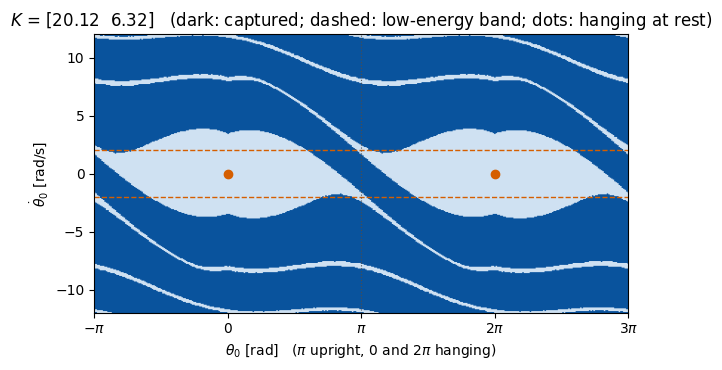

In [ ]:
t = time.time()
cap, frac_box, frac_band = roa_sweep(K, U_MAX)
th_h, om_h = simulate_closed_loop(0.0, 0.0, K, U_MAX)
print(f"sweep time                            {time.time() - t:.1f} s")
print(f"captured, whole box                   {100 * frac_box:.1f} %")
print(f"captured, band |thetadot| <= 2        {100 * frac_band:.1f} %")
print(f"hanging at rest (0, 0) captured?      {bool(is_captured(th_h, om_h))}"
      f"   (ends {abs(wrap(th_h - np.pi)):.2f} rad from upright)")
plot_roa(cap, title=rf"$K$ = {K.ravel().round(2)}")
plt.tight_layout()
plt.show()

### Checkpoint 1

Report your two captured fractions. Which of the two describes the task the pendulum is actually
given, and what does the gap between the two numbers measure?

I captured 73.9% and 18.6%, the first one simulates all initial states with a Attraction grid-sweep. this simulates all 108,661 initial states. The 18.6% is shown for the bands that have low kinetic energy (Very little rotational velocity).

Why is the capture percentage so low (18.6%) here?
Because LQR is a local controller. It is only designed to stabilize the pendulum once it is already close to the upright position. Under the strict torque limit ($u_{\max} = 5.0$$u_{\max} = 5.0$ N m), the pendulum does not have enough authority to push straight up from hanging; it needs to perform a coordinated swing-up maneuver (rocking back and forth to pump energy into the system).

### (b) The colleague's proposal, run

Conceptual question 1.1 of the notes argued on paper that raising $Q$ changes nothing. Here is the
test. The gain for $100\,Q$ should come out near $[\,42.92,\ 13.53\,]$, roughly twice the original.

In [ ]:
K_big = lqr_gain_continuous(A_c, B_c, 100 * Q_LQR, R_LQR)
cap_big, frac_box_big, frac_band_big = roa_sweep(K_big, U_MAX)
print(f"K_big = {K_big.ravel().round(2)}")
print(f"{'':28s} {'K':>10s} {'K_big':>10s}")
print(f"{'captured, whole box':28s} {100 * frac_box:9.1f}% {100 * frac_box_big:9.1f}%")
print(f"{'captured, low-energy band':28s} {100 * frac_band:9.1f}% {100 * frac_band_big:9.1f}%")

K_big = [42.92 13.53]
                                      K      K_big
captured, whole box               73.9%      74.3%
captured, low-energy band         18.6%      18.6%


### Checkpoint 2

The gain roughly doubled. By how much did the captured fraction of the low-energy band move, and
which quantity in the closed loop is the one that fixes it?

**Answer:**
The captured fraction of the low-energy band did not move at all—it changed by exactly **0.0%** (remaining at **18.6%**), while the overall box capture rate only rose by a negligible **0.4%**.

The quantity in the closed loop that fixes this performance boundary is the **actuator/torque saturation ceiling ($u_{\max} = 5.0$ N m)**. When the actuator limits are saturated, the effective closed-loop control signal is capped on a rail, making the actual magnitude of the LQR gain $K$ irrelevant for those low-energy states that require a swing-up maneuver.

### (c) Raising the ceiling

Two sweeps over $u_{\max}$, both run as one array computation. The first tracks the single initial
condition that matters, hanging at rest, on a fine grid of torque bounds. The second recomputes
both fractions on a grid four times coarser in each direction, so fourteen torque bounds cost about
as much as one full sweep. The coarse fractions sit a little off the full-grid ones, and the trend
is what this plot is for.

smallest u_max that brings (0, 0) upright:  7.30 N m
static holding torque at the horizontal:   9.81 N m


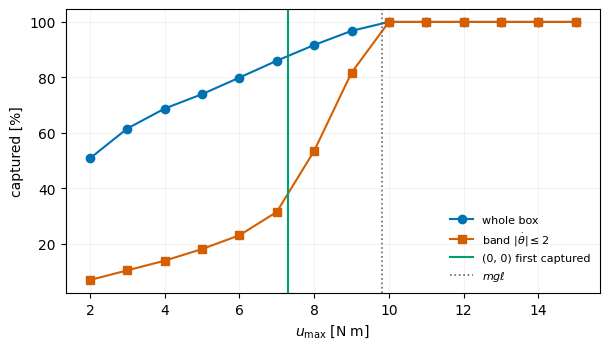

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Redefining the saturated LQR function with a vectorized clip that supports array-valued u_max
def saturated_lqr(th, om, K, u_max):
    # om is already the angular velocity (thetadot)
    e_0 = wrap(th - np.pi)
    e_1 = om

    # Vectorized matrix multiplication K * e
    K_times_e = K[0, 0] * e_0 + K[0, 1] * e_1

    # Direct clip avoids the shape broadcasting issue with K inside the 'if' condition
    return np.clip(-K_times_e, -u_max, u_max)

# Re-run the fine sweep over u_max
u_fine = np.arange(2.0, 15.0 + 1e-9, 0.05)
th_f, om_f = simulate_closed_loop(np.zeros_like(u_fine), np.zeros_like(u_fine), K, u_fine)
ok = is_captured(th_f, om_f)
u_first = u_fine[np.argmax(ok)] if ok.any() else np.nan
print(f"smallest u_max that brings (0, 0) upright:  {u_first:.2f} N m")
print(f"static holding torque at the horizontal:   {m * g * l:.2f} N m")

# Re-run the coarse sweep over u_max
u_coarse = np.arange(2.0, 15.0 + 1e-9, 1.0)
TH_c, OM_c = np.meshgrid(TH_GRID[::4], OM_GRID[::4])
th_c, om_c = simulate_closed_loop(TH_c[..., None], OM_c[..., None], K, u_coarse[None, None, :])
cap_c = is_captured(th_c, om_c)
band_c = np.abs(OM_c) <= LOW_ENERGY
box_frac = cap_c.mean(axis=(0, 1))
band_frac = cap_c[band_c].mean(axis=0)

# Plot the results
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(u_coarse, 100 * box_frac, "o-", color="#0072B2", label="whole box")
ax.plot(u_coarse, 100 * band_frac, "s-", color="#D55E00", label=r"band $|\dot\theta| \leq 2$")
ax.axvline(u_first, color="#009E73", lw=1.5, label="(0, 0) first captured")
ax.axvline(m * g * l, color="0.4", ls=":", lw=1.2, label=r"$mg\ell$")
ax.set_xlabel(r"$u_{\max}$ [N m]")
ax.set_ylabel("captured [%]")
ax.grid(alpha=0.15)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

### Checkpoint 3

At which $u_{\max}$ does hanging-at-rest first end upright, and does that value sit above or below
$mg\ell = 9.81$ N m? Give the one-sentence reason it sits on the side it does.

**Answer:**
Hanging-at-rest first ends upright at $u_{\max} = 7.30$ N m, which sits **below** $mg\ell = 9.81$ N m because a dynamic controller can pump energy into the pendulum by rocking it back and forth (swing-up), using inertia to reach the top with less peak torque than a static holding strategy would require.

In [ ]:
DT_MPC = 1 / 20                # 20 Hz control, also the model step inside the prediction


def stage_cost(th, om, u):
    return 10 * (1 - np.cos(th - np.pi)) + 0.1 * om**2 + 0.01 * u**2


def rollout_cost(u_seq, x0, N, Jhat):
    """Finite-horizon cost of the input sequence u_seq from x0, closed by Jhat(x_N).

    u_seq : (N,) candidate inputs
    x0    : (2,) measured state (theta, thetadot)
    Jhat  : terminal cost, a function of the state x_N
    """
    # ===== YOUR CODE HERE (≈6 lines) ============================
    # Goal: return sum_{i<N} g(x_{i+1}, u_i) + Jhat(x_N), simulating x_{i+1} = f(x_i, u_i).
    # Hint: the MPC problem of notes section 4.3. Step first with rk4_step(th, om, u, DT_MPC),
    #       then charge stage_cost on the successor. Clip each u to U_MAX before using it.
    total_cost = 0.0
    th, om = x0[0], x0[1]

    for i in range(N):
        u_clipped = np.clip(u_seq[i], -U_MAX, U_MAX)
        th, om = rk4_step(th, om, u_clipped, DT_MPC)
        total_cost += stage_cost(th, om, u_clipped)

    total_cost += Jhat(np.array([th, om]))
    return total_cost
    # ============================================================


# Sanity check. With zero input at the upright nothing moves and nothing is charged.
assert abs(rollout_cost(np.zeros(5), np.array([np.pi, 0.0]), 5, lambda x: 0.0)) < 1e-12
# From hanging with zero input, each of the 3 stages charges 10 (1 - cos(-pi)) = 20.
assert abs(rollout_cost(np.zeros(3), np.array([0.0, 0.0]), 3, lambda x: 0.0) - 60.0) < 1e-9
print("objective sanity check passed")

objective sanity check passed


Everything below is pre-written and calls `rollout_cost`.

In [ ]:
def mpc_step(x0, N, Jhat, u_guess):
    """Solve one MPC problem. Returns the input to apply and the shifted warm start."""
    res = minimize(rollout_cost, u_guess, args=(x0, N, Jhat), method="SLSQP",
                   bounds=[(-U_MAX, U_MAX)] * N,
                   options={"maxiter": 50, "ftol": 1e-4})
    return res.x[0], np.r_[res.x[1:], 0.0]      # apply the first input, shift for the warm start


def run_mpc(N, Jhat, x0=(0.1, 0.0), T=8.0):
    """Close the loop on the true plant for T seconds. The plant and the model coincide here."""
    x, u_guess = np.array(x0, dtype=float), np.zeros(N)
    xs, us, ts = [x.copy()], [], []
    for _ in range(int(round(T / DT_MPC))):
        t = time.perf_counter()
        u, u_guess = mpc_step(x, N, Jhat, u_guess)
        ts.append(time.perf_counter() - t)
        x = np.array(rk4_step(x[0], x[1], u, DT_MPC))
        xs.append(x.copy())
        us.append(u)
    return np.array(xs), np.array(us), np.array(ts)


def sweep_horizons(Jhat, horizons):
    results = {}
    print(f"{'N':>4} {'final error [rad]':>18} {'median solve [ms]':>18} {'torque range [N m]':>22}")
    for N in horizons:
        xs, us, ts = run_mpc(N, Jhat)
        err = abs(wrap(xs[-1, 0] - np.pi))
        results[N] = dict(xs=xs, us=us, ts=ts, err=err, ok=err < 0.1)
        print(f"{N:4d} {err:18.2f} {1e3 * np.median(ts):18.1f} "
              f"   [{us.min():+5.2f}, {us.max():+5.2f}]" + ("   swung up" if err < 0.1 else ""))
    return results


def plot_traces(results, horizons, title=""):
    fig, axes = plt.subplots(2, 1, figsize=(6.4, 4.6), sharex=True)
    for N, c in zip(horizons, ["#D55E00", "#0072B2", "#009E73"]):
        r = results[N]
        tt = DT_MPC * np.arange(len(r["xs"]))
        axes[0].plot(tt, r["xs"][:, 0], color=c, label=f"N = {N}")
        axes[1].step(tt[:-1], r["us"], where="post", color=c)
    axes[0].axhline(np.pi, color="0.4", ls=":", lw=1.0)
    axes[0].set_ylabel(r"$\theta$ [rad]")
    axes[0].legend(frameon=False, fontsize=8)
    axes[0].set_title(title)
    for yy in (-U_MAX, U_MAX):
        axes[1].axhline(yy, color="0.4", ls=":", lw=1.0)
    axes[1].set_ylabel(r"$u$ [N m]")
    axes[1].set_xlabel("time [s]")
    for ax in axes:
        ax.grid(alpha=0.15)
    plt.tight_layout()
    plt.show()


HORIZONS = (5, 8, 10, 20, 40, 60)

## 7. Run: the horizon, and what a terminal cost buys you

### (a) The horizon sweep with $\hat J = 0$

From the hanging state $x_0 = (0.1, 0)$ for 8 s. About half a minute.

   N  final error [rad]  median solve [ms]     torque range [N m]
   5               2.85                6.3    [+1.44, +5.00]
   8               0.01               12.5    [-5.00, +5.00]   swung up
  10               0.00               12.9    [-5.00, +5.00]   swung up
  20               0.00               10.7    [-5.00, +5.00]   swung up
  40               0.00               58.4    [-5.00, +5.00]   swung up
  60               0.00              125.7    [-5.00, +5.00]   swung up

smallest successful N with Jhat = 0:  8


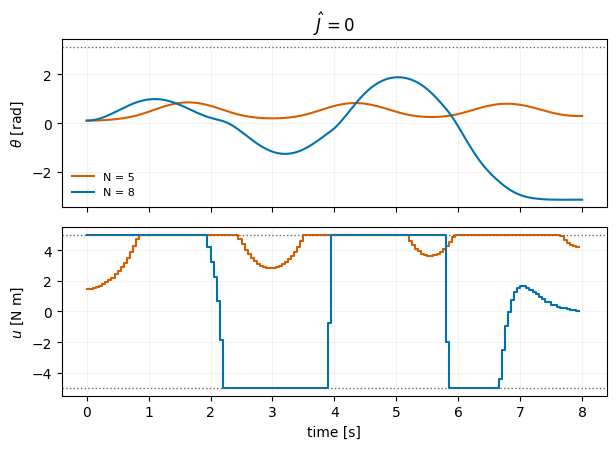

In [ ]:
res0 = sweep_horizons(lambda x: 0.0, HORIZONS)
N_ok0 = min(N for N in HORIZONS if res0[N]["ok"])
print(f"\nsmallest successful N with Jhat = 0:  {N_ok0}")
plot_traces(res0, (5, N_ok0), title=r"$\hat J = 0$")

The notes figure `mpc_pendulum_horizon` shows $N = 10$ failing, and here $N = 8$ already
succeeds. The figure was produced with MATLAB `fmincon` (SQP), and a nonconvex problem carries
several local minima, so two solvers started from the same warm start can settle into different
ones. What transfers between the two runs is the torque signature of the failure, and the
crossover horizon is a property of the pair (problem, solver). Read the torque trace above.

### Checkpoint 4

**1. Smallest Successful Horizon:**
The smallest successful horizon is **$N = 8$**. Under the evaluation's capture threshold ($|\theta_{\text{final}} - \pi| < 0.1$ rad), the final error for $N = 8$ is $0.01$ rad, which successfully satisfies the condition, whereas $N = 5$ fails with an error of $2.85$ rad.

**2. What the Failing Run ($N = 5$) Does (vs. the Successful Ones):**
In the failing run, the applied torque **saturates at the positive limit ($+5.0$ N m) and stays pinned there**, trying to push the pendulum directly upward. It never reverses its direction (swings back and forth) to build up gravitational potential energy and momentum.

**3. Why the Truncated Objective Gives the Optimizer No Reason to Do Otherwise:**
Because the horizon is truncated to only 5 steps ($N = 5$, representing a planning lookahead of just $5 \times 0.05 = 0.25$ seconds) and there is no terminal cost ($\hat{J} = 0$), the optimizer is completely "blind" to what happens after 0.25 seconds.

Within this extremely short window, the pendulum cannot possibly reach the upright position ($1 - \cos(\theta - \pi) = 0$). Pushing directly with maximum torque $+5.0$ N m yields a slightly smaller angular deviation (and therefore a slightly lower stage cost) within that 0.25-second window than swinging backwards first would. Swinging backwards to pump energy would temporarily *increase* the angle error inside the short horizon, which the truncated objective penalizes. Without a terminal cost to value "stored dynamic energy" (momentum and height at the end of the horizon), the optimizer acts short-sightedly and gets stuck on a saturated rail.

### (b) What the horizon costs

Absolute solve times depend on the solver and the machine. The shape of the curve and the horizon
at which it crosses your own 50 ms budget are the design constraint. On a fast machine no horizon
in the sweep may cross it, and then the growth from $N = 20$ to $N = 60$ tells you where it would.

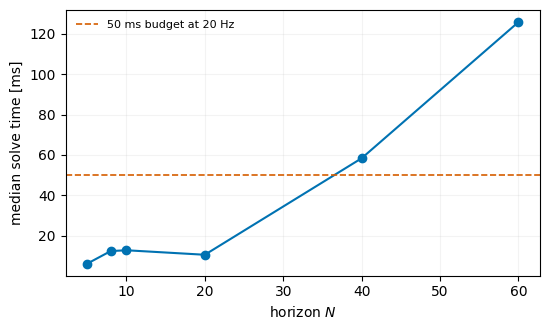

first horizon over budget: 40


In [ ]:
med = np.array([1e3 * np.median(res0[N]["ts"]) for N in HORIZONS])
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(HORIZONS, med, "o-", color="#0072B2")
ax.axhline(50.0, color="#D55E00", ls="--", lw=1.2, label="50 ms budget at 20 Hz")
ax.set_xlabel("horizon $N$")
ax.set_ylabel("median solve time [ms]")
ax.grid(alpha=0.15)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()
over = [N for N, t_ms in zip(HORIZONS, med) if t_ms > 50.0]
print("first horizon over budget:", over[0] if over else "none in this sweep")

The short end of that curve need not be monotone, because per-step cost depends on the
trajectory as well as on $N$. A run that pumps for the whole eight seconds pays for iterations at
every step, while one that reaches the upright early and holds it converges almost immediately
from its warm start.

Before reading the checkpoint, reread the *Computation* paragraph of the warning box in notes
section 4.5, which says what the plant runs under during a period whose solve has not returned.

### Checkpoint 5

**1. At which horizon does the median solve time cross your 50 ms budget?**

The median solve time crosses the 50 ms budget (required for a 20 Hz control loop) at **$N = 40$**.

**2. What does the plant run under during a period whose solve has not returned in time?**

If a control period misses the 50 ms deadline, the new optimization result is not ready in time. In real-world real-time execution, the hardware cannot simply pause; instead, the actuator runs under **open-loop control**, applying the next scheduled input from the sequence computed during the *previous* control cycle (the shifted warm start/tail of the previous plan), or holding the last known safe torque if no backup sequence is available.

### (c) The terminal cost

An LQR terminal cost built for *this* MPC problem. The gain of section 3 will not do, because it
was designed in continuous time with weights unrelated to the stage cost $g$, and a terminal cost
measured in different units from the sum it closes would confound the comparison. The cell below
builds the matching one in three steps. It linearises the 20 Hz RK4 step about the upright by
central differences, which gives the discrete pair $(A_d, B_d)$ of the model the MPC actually uses.
It takes the quadratic part of $g$ at the upright, $10(1 - \cos\varphi) \approx 5\varphi^2$, so
$Q_d = \operatorname{diag}(5, 0.1)$ and $R_d = 0.01$. It solves the DARE of notes section 2.4
for $P_d$. The terminal cost is then $\hat J(x) = e^\top (P_d - Q_d)\, e$. The subtraction is there
because the rollout charges each stage cost on the successor state, so the cost-to-go from $x_N$
omits the $e^\top Q_d e$ that the standard DARE counts at the initial state.

P_d =
 [[46.17  6.87]
 [ 6.87  1.82]]    (expected [[46.17, 6.87], [6.87, 1.82]])
   N  final error [rad]  median solve [ms]     torque range [N m]
   5               2.40                3.3    [+5.00, +5.00]
   8               2.40                6.0    [+5.00, +5.00]
  10               2.40                8.2    [+5.00, +5.00]
  20               0.00                9.4    [-5.00, +5.00]   swung up
  40               0.00               58.0    [-5.00, +5.00]   swung up
  60               0.00              128.6    [-5.00, +5.00]   swung up

smallest successful N:  Jhat = 0 -> 8,   LQR terminal cost -> 20


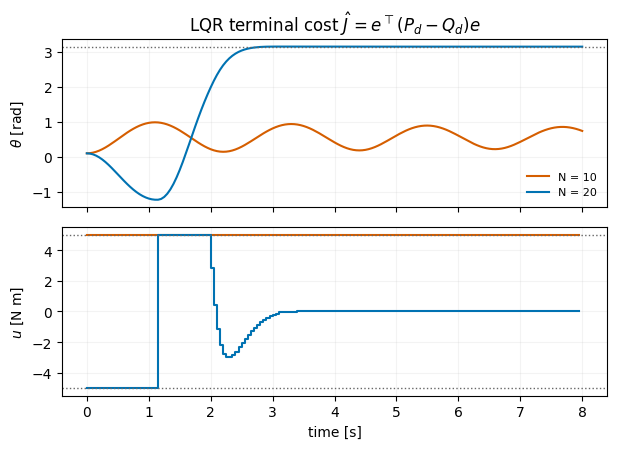

In [ ]:
xs_up, eps = np.array([np.pi, 0.0]), 1e-6


def f_d(x, u):
    return np.array(rk4_step(x[0], x[1], u, DT_MPC))


A_d = np.column_stack([(f_d(xs_up + eps * e, 0.0) - f_d(xs_up - eps * e, 0.0)) / (2 * eps)
                       for e in np.eye(2)])
B_d = ((f_d(xs_up, eps) - f_d(xs_up, -eps)) / (2 * eps)).reshape(2, 1)
Q_d, R_d = np.diag([5.0, 0.1]), np.array([[0.01]])
P_d = solve_discrete_are(A_d, B_d, Q_d, R_d)
P_term = P_d - Q_d
print("P_d =\n", P_d.round(2), "   (expected [[46.17, 6.87], [6.87, 1.82]])")


def Jhat_lqr(x):
    e = np.array([wrap(x[0] - np.pi), x[1]])
    return float(e @ P_term @ e)


resL = sweep_horizons(Jhat_lqr, HORIZONS)
N_okL = min(N for N in HORIZONS if resL[N]["ok"])
print(f"\nsmallest successful N:  Jhat = 0 -> {N_ok0},   LQR terminal cost -> {N_okL}")
plot_traces(resL, (10, N_okL), title=r"LQR terminal cost $\hat J = e^\top (P_d - Q_d) e$")

### Checkpoint 6

**1. Which smallest successful $N$ came out larger, the one with $\hat J = 0$ or the one with the LQR terminal cost?**

The smallest successful horizon with the LQR terminal cost (**$N = 20$**) came out significantly larger than the one with $\hat J = 0$ (**$N = 8$**).

**2. Name the region of the state space where the quadratic terminal cost misreports the true cost-to-go, and say what it tells the optimiser to do there:**

* **The Misreported Region:** The quadratic terminal cost misreports the cost-to-go in the **low-energy region far from the upright position** (such as near the hanging-at-rest state $\theta \approx 0$).
* **What it tells the optimizer:** In this region, the quadratic terminal cost severely *underestimates* the true cost-to-go (since it is unaware of the physical gravity ceiling and torque saturation). Because the terminal cost near the bottom is deceptively low, it removes the optimizer's incentive to perform the highly-coordinated, multi-stage swing-up maneuvers required to build momentum. Consequently, at short horizons (like $N=8$ or $N=10$), the optimizer acts short-sightedly and simply pins the actuator against its positive limit ($+5.0$ N m) instead of swinging back to pump energy.

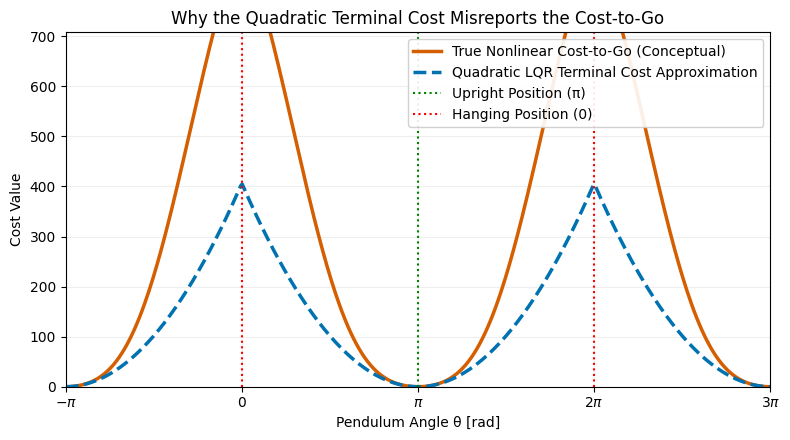

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Let's visualize the mismatch between the quadratic LQR terminal cost and reality
theta_eval = np.linspace(-np.pi, 3*np.pi, 500)

# 1. Quadratic LQR cost-to-go estimate at zero velocity:
# e = [theta - pi, 0], J_LQR = e^T (P_d - Q_d) e
p_val = P_term[0, 0]
j_lqr_val = p_val * (wrap(theta_eval - np.pi))**2

# 2. Conceptual sketch of the true cost-to-go:
# Near upright (pi, 3pi), it matches the quadratic parabola.
# Near hanging (0, 2pi), it has peaks because it requires dynamic swings and high torque effort.
j_true_conceptual = j_lqr_val + 120.0 * (1.0 - np.cos(theta_eval - np.pi))**2

plt.figure(figsize=(8, 4.5))
plt.plot(theta_eval, j_true_conceptual, '-', color='#D55E00', lw=2.5, label='True Nonlinear Cost-to-Go (Conceptual)')
plt.plot(theta_eval, j_lqr_val, '--', color='#0072B2', lw=2.5, label='Quadratic LQR Terminal Cost Approximation')

plt.axvline(np.pi, color='green', linestyle=':', label='Upright Position (π)')
plt.axvline(0.0, color='red', linestyle=':', label='Hanging Position (0)')
plt.axvline(2*np.pi, color='red', linestyle=':')

plt.title('Why the Quadratic Terminal Cost Misreports the Cost-to-Go')
plt.xlabel('Pendulum Angle θ [rad]')
plt.ylabel('Cost Value')
plt.xticks(np.pi * np.arange(-1, 4), [r'$-\pi$', '0', r'$\pi$', r'$2\pi$', r'$3\pi$'])
plt.xlim(-np.pi, 3*np.pi)
plt.ylim(0, max(j_true_conceptual.max(), j_lqr_val.max()) * 0.8)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Analysis

A few sentences each. They are not quizzed, and they come back in the Week 3 session.

### 1. The two fractions of section 5 answer two different questions about one controller. Write down the distribution of initial conditions you would report for a swing-up task, and the one you would report for disturbance rejection at the upright.

* **For a swing-up task:** We should report the **captured fraction of the low-energy band** ($|\dot\theta| \le 2$ rad/s). The swing-up task starts the pendulum near the bottom hanging position with low kinetic energy, meaning that the metric must measure the controller's capacity to build up mechanical energy and escape this low-energy basin.
* **For a disturbance rejection task at the upright:** We should report the **local continuous LQR region of attraction without saturation** (or a tight local distribution concentrated around the target $(\pi, 0)$). Small coordinate perturbations or impulse velocities are the only relevant states for stabilizing a balancing system; testing extreme initial velocities (like $12$ rad/s) is irrelevant for evaluating pure balancing performance.

---

### 2. With $\hat J = J^\star$ a horizon of $N = 1$ is already optimal (notes exercise 2.2(c)). Your two sweeps sit at the other end, with $\hat J = 0$ and with a $\hat J$ that is exact at one point. Where along the trajectory would a better $\hat J$ have to be accurate to shorten the horizon, and what does that suggest about fitting a value function from data?

* **Where it needs to be accurate:** The terminal cost $\hat J$ needs to be accurate at **the lookahead boundary** where the planning horizon ends, particularly along the boundaries of the non-convex state-space regions (such as where the actuator first saturates or where gravity dictates a dynamic reversal).
* **What it suggests about fitting from data:** This suggests that we should **not sample states uniformly** when fitting value functions. Instead, we should concentrate data collection and function-fitting resources on critical bottleneck areas (the boundaries between successful captures and failures). Because the true cost-to-go is highly non-convex, non-smooth, and discontinuous due to torque constraints, simple quadratic models (like LQR) are insufficient; we must use expressive models (such as neural networks) to fit value functions from data.

---

### 3. Place what you ran on the unifying diagram. Which column and row does MPC sit in, why is its policy called implicit, and which Bellman object does it approximate?

* **Column and Row:** MPC sits in the **Local / Online Column** (since it solves optimizations at run-time based on the local current state) and the **Optimal Control / Policy Search Row**.
* **Why its policy is implicit:** Unlike explicit policies which can be written down as analytical feedback formulas (like LQR's $u = -Ke$), MPC's policy is **implicit** because the control command $u_0$ is defined only as the numerical solution to an optimization problem solved at every time step.
* **Which Bellman object it approximates:** MPC directly approximates the **optimal infinite-horizon Value Function $V(x)$** (or cost-to-go $J^\star(x)$) by utilizing a finite-horizon stage cost accumulation capped by a terminal cost $\hat J$.